### Iris Flower Classification Model using Decision Trees

- This is the second model I will build to deepen ML algorithm competency. This model will be guided by an LLM, with minimal code given, and only when I am unable to figure out the code myself.

- The goal is to train a ML model to identify a species of iris flower based on four physical measurements.

- If a flower's measurements are given, the model should be able to predict the species.

- The difference between this model and the first, logistic regression model, is that this model with evaluate with a decision tree. The tree will learn a series of rules that divide the data into increasingly homogeneous groups. 

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import multilabel_confusion_matrix # allows us to print out the cm's 
from sklearn.metrics import classification_report
from sklearn.tree import plot_tree


iris = load_iris()

X = iris.data
y = iris.target

### Get basic information about the dataset

- Shape of X: How many observations and features do we have?
- Shape of y: How many target labels do we have?
- Feature names: What are the four features?
- Target names: What are the three flower species?
- Class distribution: How many observations belong to each species?

In [2]:
# Get some information about the dataset

def model_info(X, y, feature_names, target_names):
    
    features_shape = X.shape
    labels_shape = y.shape
    
    feat_names = iris.feature_names
    target_names = iris.target_names
    
    species_distribution = np.unique(y, return_counts=True)

In [3]:
# lets turn it into a function

def model_info(X, y, feature_names, target_names):
    
    features_shape = X.shape
    labels_shape = y.shape
    
    feat_names = feature_names
    target_names = target_names
    
    species_distribution = np.unique(y, return_counts=True)
    
    return (features_shape, labels_shape, feat_names, target_names, species_distribution)

info = model_info(X, y, iris.feature_names, iris.target_names)
    

In [4]:
"""Returning like that produces a tuple, which allows us to access the data with indexing"""

print(info[0])

(150, 4)


In [5]:
# turn X into a pandas dataframe
feat_names = iris.feature_names
df = pd.DataFrame(data=X, columns=feat_names)
df["species"] = y
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
# create model and split data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [7]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(120, 4)
(30, 4)
(120,)
(30,)


In [8]:
# create the decision tree
# train data
# generate predictions for X_test
# store in y_pred
# display 10

tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)
y_pred = tree_model.predict(X_test)


In [9]:
# generate training and testing accuracy

y_train_pred = tree_model.predict(X_train) # accuracy_score req's prediction

train_accuracy = accuracy_score(y_train, y_train_pred) * 100
test_accuracy = accuracy_score(y_test, y_pred) * 100

print(f"Training Accuracy: {train_accuracy:.2f}%")
print(f"Testing Accuracy: {test_accuracy:.2f}%")

Training Accuracy: 98.33%
Testing Accuracy: 96.67%


### Turn the model creation code into functions


In [10]:
"""function should take 3 parameters, initialize decision tree, 
fit it to training data, and return trained model"""

def train_tree(X_train, y_train, max_depth):
    
    # initialize decision tree model
    tree = DecisionTreeClassifier(max_depth=max_depth, random_state=42)

    # fit training data
    tree.fit(X_train, y_train)

    return tree
    

tree_model = train_tree(X_train, y_train, max_depth=3)
tree_model

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [11]:
""" create func that generates predictions for training/testing data
    calc training/testing accuracy, return both accuracy scores"""

def evaluate_tree(model, X_train, X_test, y_train, y_test):
    y_train_predict = model.predict(X_train)
    y_test_predict = model.predict(X_test)

    test_accuracy = accuracy_score(y_test, y_test_predict) * 100
    train_accuracy = accuracy_score(y_train, y_train_predict) * 100

    return train_accuracy, test_accuracy

train_acc, test_acc = evaluate_tree(tree_model, X_train, X_test, y_train, y_test)
print(f"Training accuracy: {train_acc:.2f}%")
print(f"Testing accuracy: {test_acc:.2f}%")

Training accuracy: 98.33%
Testing accuracy: 96.67%


### Train the model with different depths by invoking the functions created above 

In [12]:
depths = [2, 3, 5, 10]

for depth in depths:
    # train the tree, evaluate the tree, print results
    tree_creation = train_tree(X_train, y_train, depth)
    training_acc, testing_acc = evaluate_tree(tree_creation, X_train, X_test, y_train, y_test)

    print(f"Depth:{depth}")
    print(f"Training Accuracy: {training_acc:.2f}%")
    print(f"Testing Accuracy: {testing_acc:.2f}%")
    print(f"Tree depth: {tree_creation.get_depth()}")
    print(f"Number of leaf nodes: {tree_creation.get_n_leaves()}")
    print()

Depth:2
Training Accuracy: 96.67%
Testing Accuracy: 93.33%
Tree depth: 2
Number of leaf nodes: 3

Depth:3
Training Accuracy: 98.33%
Testing Accuracy: 96.67%
Tree depth: 3
Number of leaf nodes: 5

Depth:5
Training Accuracy: 100.00%
Testing Accuracy: 93.33%
Tree depth: 5
Number of leaf nodes: 8

Depth:10
Training Accuracy: 100.00%
Testing Accuracy: 93.33%
Tree depth: 5
Number of leaf nodes: 8



### When the tree reached depths 5, 10 - we get identical results. This may mean that the tree did not grow to those depths. This can be checked using the get_depth() on the tree

In [13]:
tree_creation.get_depth()

5

### Create Confusion Matrix

In [27]:
tree_model = train_tree(X_train, y_train, max_depth=3)

# get y_pred to create cm
y_pred = tree_model.predict(X_test)

# create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# We can use the multilabel_confusion_matrix to get 
matrices = multilabel_confusion_matrix(y_test, y_pred)
matrices

# TN FN | FP TP

array([[[20,  0],
        [ 0, 10]],

       [[20,  0],
        [ 1,  9]],

       [[19,  1],
        [ 0, 10]]])

- Class 0 = Setosa
- Class 1 = Versicolor
- Class 2 = Virginica

In [26]:
# We can use classification report to print out the cm values with labels
print(classification_report(
    y_test, 
    y_pred, 
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



[Text(0.375, 0.875, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 120\nvalue = [40, 40, 40]\nclass = setosa'),
 Text(0.25, 0.625, 'gini = 0.0\nsamples = 40\nvalue = [40, 0, 0]\nclass = setosa'),
 Text(0.3125, 0.75, 'True  '),
 Text(0.5, 0.625, 'petal width (cm) <= 1.65\ngini = 0.5\nsamples = 80\nvalue = [0, 40, 40]\nclass = versicolor'),
 Text(0.4375, 0.75, '  False'),
 Text(0.25, 0.375, 'petal length (cm) <= 4.95\ngini = 0.133\nsamples = 42\nvalue = [0, 39, 3]\nclass = versicolor'),
 Text(0.125, 0.125, 'gini = 0.0\nsamples = 38\nvalue = [0, 38, 0]\nclass = versicolor'),
 Text(0.375, 0.125, 'gini = 0.375\nsamples = 4\nvalue = [0, 1, 3]\nclass = virginica'),
 Text(0.75, 0.375, 'petal length (cm) <= 4.85\ngini = 0.051\nsamples = 38\nvalue = [0, 1, 37]\nclass = virginica'),
 Text(0.625, 0.125, 'gini = 0.444\nsamples = 3\nvalue = [0, 1, 2]\nclass = virginica'),
 Text(0.875, 0.125, 'gini = 0.0\nsamples = 35\nvalue = [0, 0, 35]\nclass = virginica')]

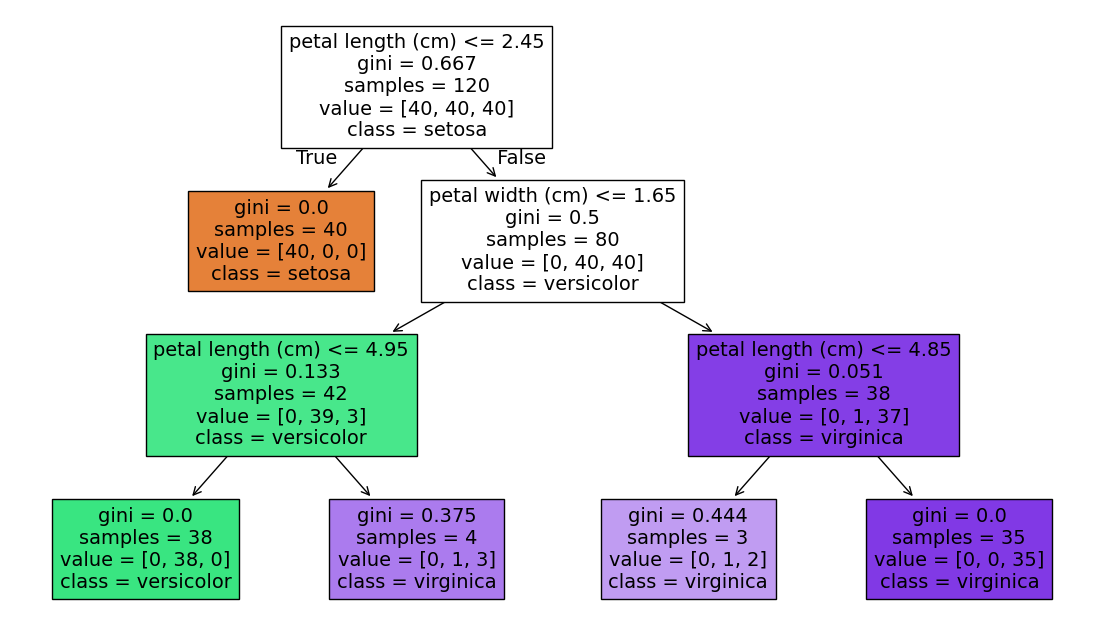

In [31]:
# visualize the tree model

plt.figure(figsize=(14,8))

plot_tree(tree_model, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)